In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import tifffile as tiff
import numpy as np

root_dir = Path.cwd().parents[2]
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))


from utils.display_videos import display_videos
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.motion_correct_preprocessing import save_data_as_tif

from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_correlation import diagnose_resonant_scan, frame_difference_noise, spatial_noise_correlation
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    fit_joint_resonant_covariance,
)

fig_path = root_dir.parent / "figures" / "resonancescanningfixes"


## ToDo:
* build methods for preprocessing & alignment template generation
* automatically save / load expensive steps
* wrapper for saving / calling movie, if necessary
* adjustment of TiffAlign to take in arrays and properly sized data (tiffs in stacks!)

In [3]:
session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*m.tif"))
file_path = paths[0]
file_path

PosixPath('/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01/ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am.tif')

In [ ]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection.utils.build_alignment_template import build_alignment_template
movie = tiff.imread(file_path).astype("float32")
k = max(int(movie.shape[0] * 0.05), 100)


seed frame: 7448
similarity score: 0.46559048


  0%|          | 0/201 [00:00<?, ?it/s]

In [16]:
k=100
template, aligned = build_alignment_template(movie, N_iter=1, k=k, plot=False)


seed frame: 6714
similarity score: 0.7419417


  0%|          | 0/101 [00:00<?, ?it/s]

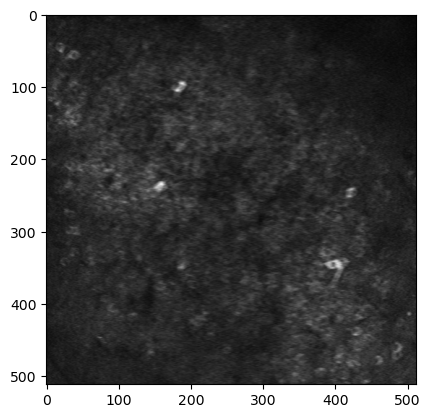

In [17]:
from matplotlib import pyplot as plt
plt.figure()
plt.imshow(template, cmap='gray')
plt.show()


In [13]:
(template - template.min())/(template.max() - template.min())

array([[0.00027443, 0.03859559, 0.04463609, ..., 0.0071459 , 0.0092628 ,
        0.00586294],
       [0.05874252, 0.11501498, 0.10744885, ..., 0.02847358, 0.03274673,
        0.03335856],
       [0.06383457, 0.12338686, 0.13664009, ..., 0.02878536, 0.02667828,
        0.0366108 ],
       ...,
       [0.08275046, 0.15038821, 0.14380991, ..., 0.20944992, 0.21425457,
        0.22112326],
       [0.09167305, 0.1419196 , 0.1406177 , ..., 0.22500536, 0.22067285,
        0.20247489],
       [0.0728593 , 0.13389194, 0.12276812, ..., 0.22228087, 0.21976875,
        0.21634024]], dtype=float32)

In [18]:
import cv2

figure_dir = Path(".") / "figures"
figure_dir.mkdir(exist_ok=True, parents=True)
background_path = figure_dir / f"template_test.png"
cv2.imwrite(str(background_path), (template - template.min())/(template.max() - template.min())*255, [cv2.IMWRITE_PNG_COMPRESSION, 0])


True

In [ ]:
# movie_m845ad = tiff.imread(file_path).astype("float32")

In [7]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection import motion_correct
from turnover_dynamics.neuron_detection_caiman.neuron_detection.utils.parameters import (
    CaImAn as CaImAn_params,
)

import copy

params = copy.deepcopy(CaImAn_params)
params["show_movie"] = False  # whether to display movie while fitting

params["fr"] = 15.0
params["decay_time"] = 0.47
params["pw_rigid"] = True
params["max_shifts"] = (12, 12)
params["strides"] = (96, 96)
params["overlaps"] = (32, 32)

motion_correct(
    file_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=1,
    # template=template,
    plot=True,
)

	Now running motion correction @t = Tue Oct 20 17:50:06 2026
Building alignment template @t = Tue Oct 20 17:50:06 2026
seed frame: 6714
similarity score: 0.7444143


NameError: name 'align_template_candidates' is not defined

In [4]:
session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]
movie_m493 = tiff.imread(file_path).astype("float32")

In [5]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.motion_correct_preprocessing import (
    run_diagnostics,
    resample_and_equalize,
)

results = run_diagnostics(movie_m845ad, session_path / "correction")
resampler = resample_and_equalize(results["diagnostics"], results["joint_fit"], n=256)

Running diagnostics and fitting joint resonant covariance for save path: /home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01/correction/diagnostics_and_fit.pkl...


AttributeError: module 'numpy' has no attribute 'trapezoid'

In [5]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_downsampling import (
    direct_theta_downsample_movie,
)

movie_resampled = direct_theta_downsample_movie(
    movie_m845ad,  # [:4000,...],
    resampler,
)

In [7]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.motion_correct_preprocessing import (
    build_alignment_template,
    check_coherence,
)

# template, aligned = build_alignment_template(
#     movie_resampled, N_iter=2, k=100, plot=True
# )
# check_coherence(aligned, results["joint_fit"])

In [10]:
movie_m845ad.shape

(8989, 512, 512)

449
seed frame: 7448
similarity score: 0.46203595


  0%|          | 0/201 [00:00<?, ?it/s]

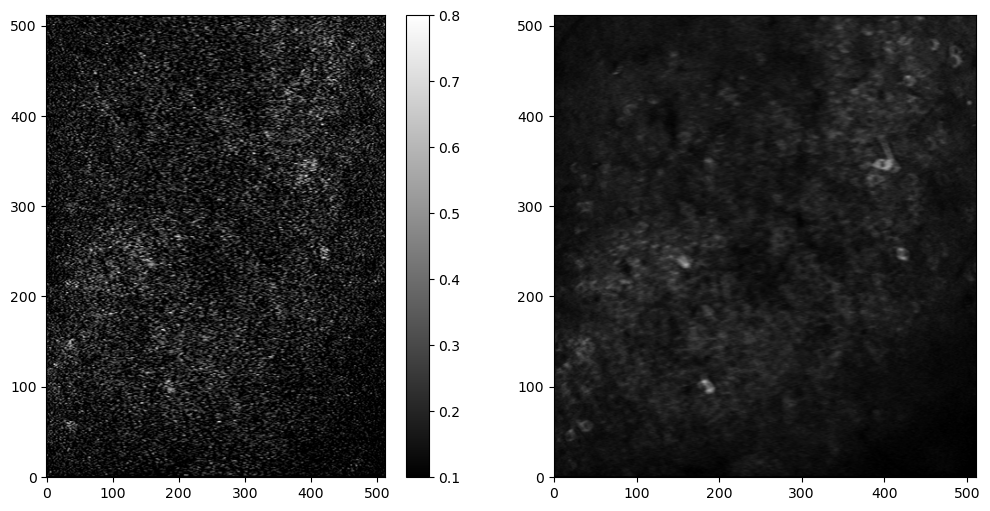

In [14]:
k = int(movie_m845ad.shape[0] * 0.05)
print(k)
template, aligned = build_alignment_template(movie_m845ad, N_iter=1, k=k, plot=True)
# check_coherence(aligned, results["joint_fit"])

seed frame: 6712
similarity score: 0.7515178


  0%|          | 0/101 [00:00<?, ?it/s]

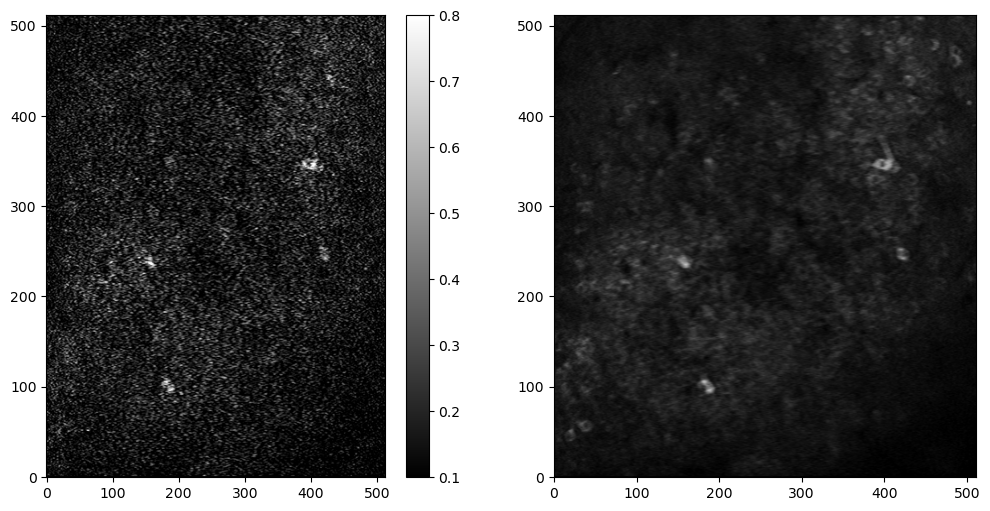

In [13]:
template, aligned = build_alignment_template(movie_m845ad, N_iter=1, k=100, plot=True)

seed frame: 7344
similarity score: 0.8884665


  0%|          | 0/101 [00:00<?, ?it/s]

  0%|          | 0/101 [00:00<?, ?it/s]

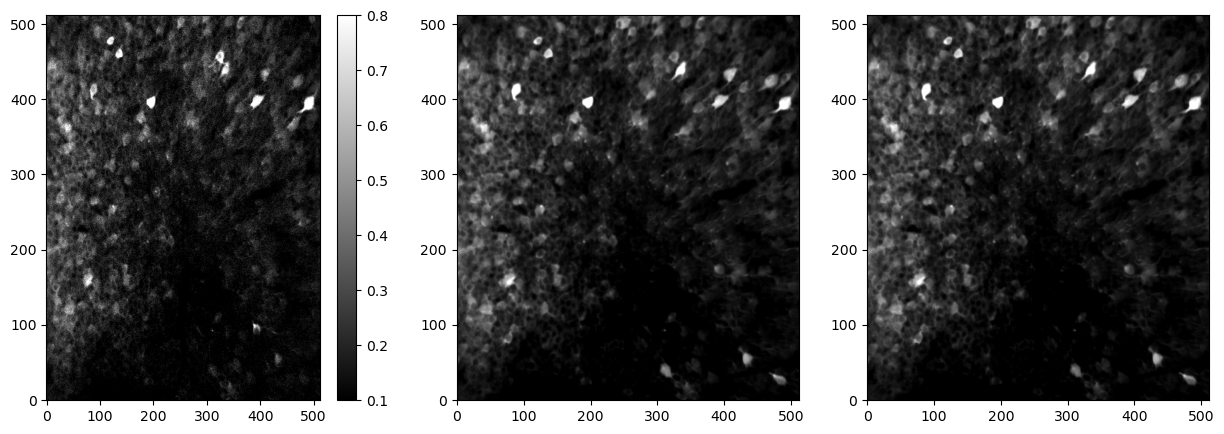

In [9]:
template, aligned = build_alignment_template(movie_m493, N_iter=2, k=100, plot=True)

## Observations
* resampling does reduce overall coherence after ~30 cyc/rad, but introduces slight coherence bump at ~40 cyc/rad
* 

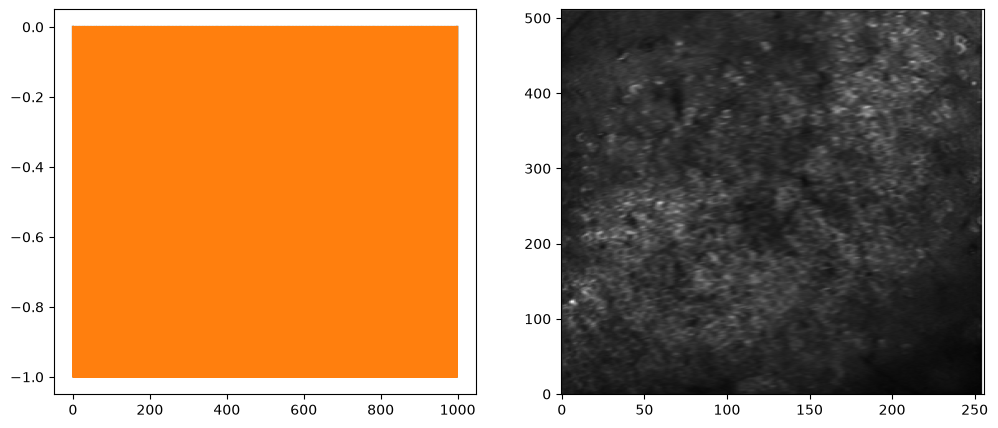

In [ ]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection.motion_correction.LK_alignment import (
    xy_align,
)
from matplotlib import pyplot as plt

res = xy_align(movie_resampled[:1000, ...], max_shift=15, template=template)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(res.T[:, 0])
axes[0].plot(res.T[:, 1])

axes[1].imshow(res.I, cmap="gray", origin="lower", aspect="auto")
plt.show()

In [22]:
res.T

array([[ 0,  0],
       [-1, -1],
       [ 0,  0],
       ...,
       [ 0,  0],
       [-1, -1],
       [ 0,  0]], shape=(1000, 2))

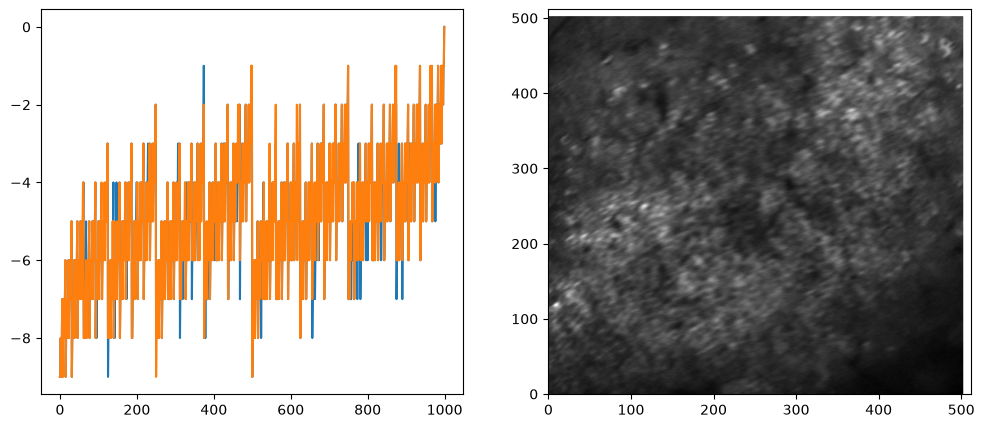

In [ ]:
res = xy_align(movie_m845ad[:1000, ...], max_shift=15)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(res.T[:, 0])
axes[0].plot(res.T[:, 1])

axes[1].imshow(res.I, cmap="gray", origin="lower", aspect="auto")
plt.show()

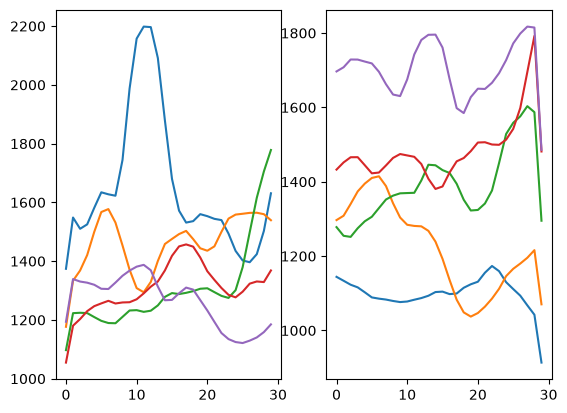

In [ ]:
mean_mov = movie_m845ad.sum(axis=0)


margins = 30
fig, axes = plt.subplots(1, 2)
axes[0].plot(mean_mov[[100, 200, 300, 400, 500], :margins].T)
axes[1].plot(mean_mov[[100, 200, 300, 400, 500], -margins:].T)
# plt.plot(mean_mov[200, :margins])
# plt.plot(mean_mov[300, :margins])
# plt.plot(mean_mov[400, :margins])
# plt.plot(mean_mov[500, :margins])
plt.show()

In [ ]:
freq_theta, coh_theta, A_half, B_half, PA, PB = split_half_theta_coherence(
    aligned[good],
    x_positions=resampler["x_out"],
    x0=joint_fit["x0"],
    A=joint_fit["A"],
)

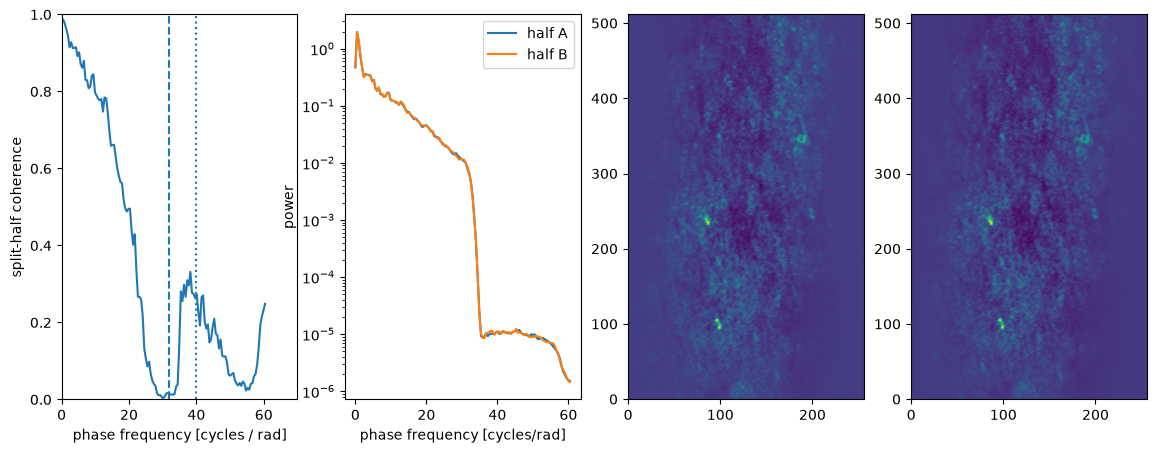

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 5))
axes[0].plot(
    freq_theta,
    coh_theta,
)
axes[0].axvline(32, ls="--")
axes[0].axvline(40, ls=":")

axes[0].set_xlim(0, 70)
axes[0].set_ylim(0, 1)

axes[0].set_xlabel("phase frequency [cycles / rad]")
axes[0].set_ylabel("split-half coherence")


axes[1].semilogy(freq_theta, PA, label="half A")
axes[1].semilogy(freq_theta, PB, label="half B")
axes[1].set_ylabel("power")
axes[1].set_xlabel("phase frequency [cycles/rad]")
axes[1].legend()


axes[2].imshow(A_half, aspect="auto", origin="lower")
axes[3].imshow(B_half, aspect="auto", origin="lower")

plt.savefig(session_path / "figures" / "coherence_of_alignment_template.png")

Text(0, 0.5, 'split-half coherence')

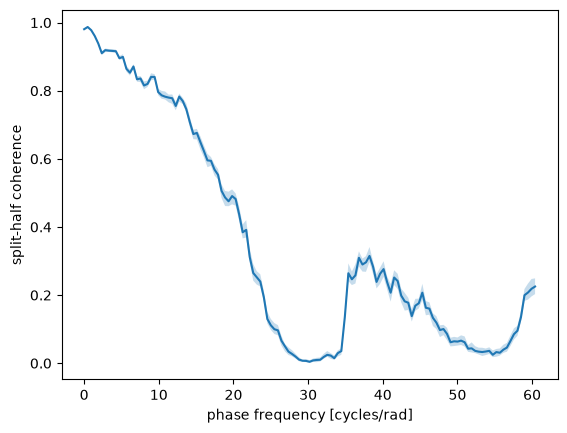

In [57]:
cohs = []

for seed in range(50):
    freq, coh, *_ = split_half_theta_coherence(
        aligned[good],
        x_positions=resampler["x_out"],
        x0=joint_fit["x0"],
        A=joint_fit["A"],
        seed=seed,
    )
    cohs.append(coh)

cohs = np.asarray(cohs)

plt.plot(
    freq,
    np.median(cohs, axis=0),
)

plt.fill_between(
    freq,
    np.percentile(cohs, 10, axis=0),
    np.percentile(cohs, 90, axis=0),
    alpha=0.25,
)

plt.xlabel("phase frequency [cycles/rad]")
plt.ylabel("split-half coherence")

# enter deconvolution

In [ ]:
# out_path = session_path / f"resampled_eq_movie.tif"
# save_data_as_tif(out_path, movie_resampled_eq, True)

  0%|          | 0/8989 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Tue Oct 20 17:04:09 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:16<00:00, 16.37s/it]


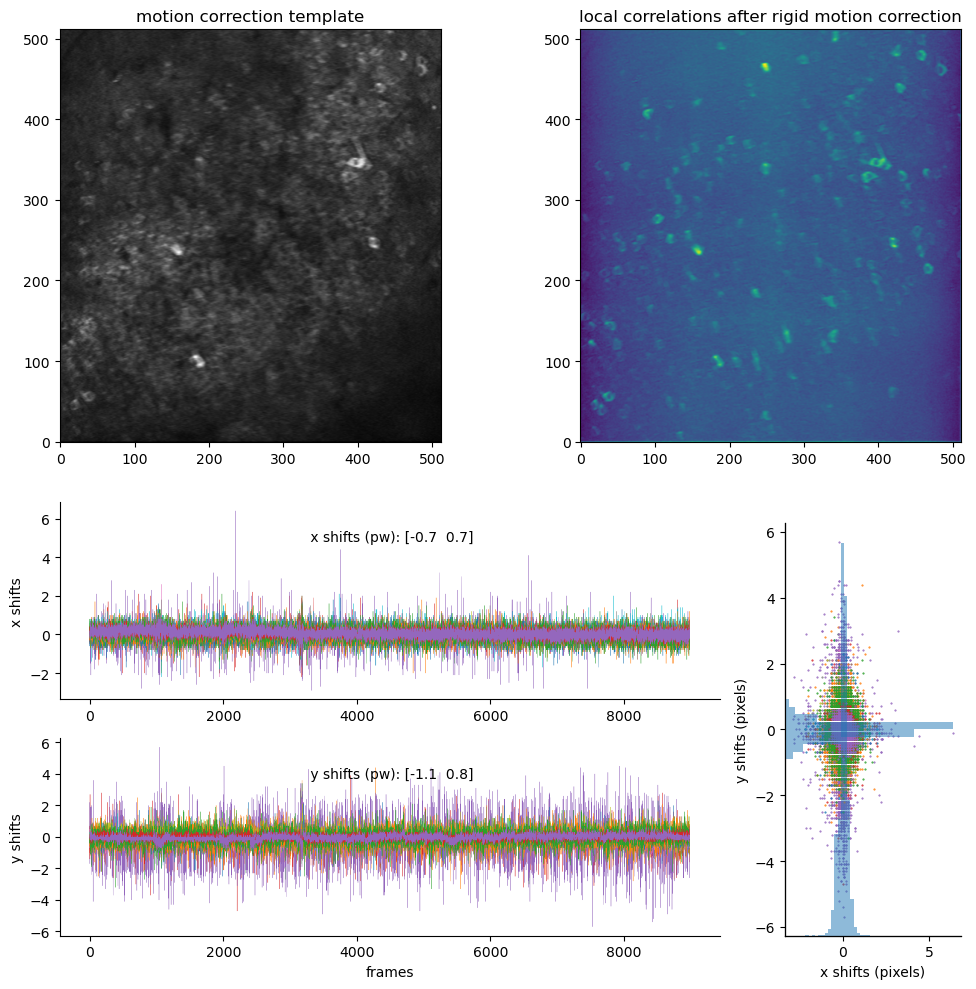

	Motion correction done @t = Tue Oct 20 17:09:56 2026, (time passed: 347.29348278045654)


'/home/wollex/caiman_data/temp/ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am_els__d1_512_d2_512_d3_1_order_F_frames_8989.mmap'

In [ ]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection import motion_correct
from caiman.source_extraction import cnmf
import copy
from turnover_dynamics.neuron_detection_caiman.neuron_detection.utils.parameters import (
    CaImAn as CaImAn_params,
)

params = copy.deepcopy(CaImAn_params)
params["show_movie"] = False  # whether to display movie while fitting
# params.update(kwargs)

n = 256
scale_factor = n / 512
# opts = cnmf.params.CNMFParams(params_dict=params)
# opts.set("motion", {
#     "max_shifts": (12,int(12*scale_factor)),
#     "strides": (96,int(96*scale_factor)),
#     "overlaps": (32,int(32*scale_factor))
# })
# opts.get_group("motion")

params["fr"] = 15.0
params["decay_time"] = 0.47
params["pw_rigid"] = True
# params["max_shifts"] = (12, int(12 * scale_factor))
# params["strides"] = (96, int(96 * scale_factor))
# params["overlaps"] = (32, int(32 * scale_factor))
params["max_shifts"] = (12, 12)
params["strides"] = (96, 96)
params["overlaps"] = (32, 32)
# print(params)

motion_correct(
    file_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=4,
    template=template,
    plot=True,
)

  0%|          | 0/4494 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Mon Aug 31 05:43:34 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  1.29it/s]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


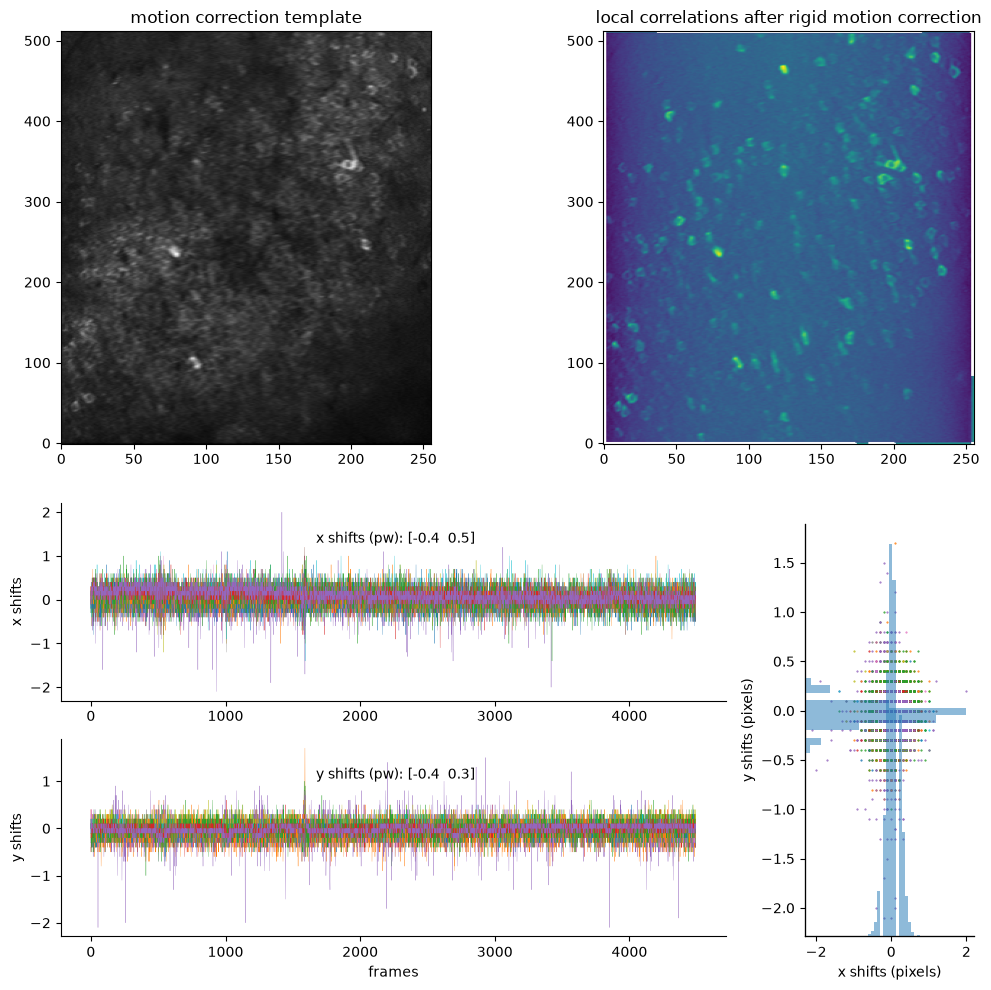

	Motion correction done @t = Mon Aug 31 05:47:16 2026, (time passed: 222.0906879901886)


'/home/wollex/caiman_data/temp/binned_resampled_eq_movie_els__d1_512_d2_256_d3_1_order_F_frames_4494.mmap'

In [61]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_binning import (
    temporal_bin_movie,
)

binned_movie, frame_centers, bin_edges = temporal_bin_movie(
    movie_resampled_eq, bin_size=2, method="mean"
)

out_path = session_path / f"binned_resampled_eq_movie.tif"
save_data_as_tif(out_path, binned_movie, True)

motion_correct(
    out_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=1,
    template=template_out,
    plot=True,
)

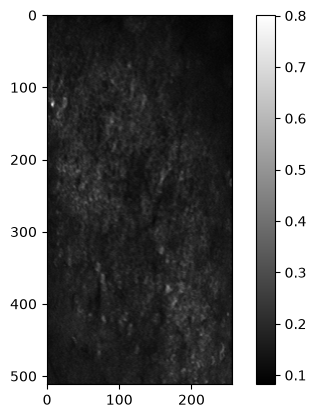

In [ ]:
fig = plt.figure()
plt.imshow(template1, cmap="gray")
plt.colorbar()
plt.show()
# template1.shape

In [ ]:
check tiffAlign input / output.
adjust, so it takes array as input & returns array as output

establish 3 motion correction methods: normcorre, tiffalign, likelihood-based


further:
implement convolution/deconvolution into the motion correction pipeline

SyntaxError: invalid syntax (3484702826.py, line 1)